In [1]:
# =====================================================================
# Olist SQL Setup — runs on BOTH Google Colab and a local machine.
# Run this cell FIRST. It loads the 8 Olist tables into a SQLite
# database and connects the %%sql magic to it. You should not need to
# edit anything unless auto-detection fails (see the two knobs below).
#
# Design notes:
# - We teach SQL with the %%sql cell magic (jupysql), not pd.read_sql().
# - jupysql opens its OWN connection, so the DB must be a real FILE
#   (a :memory: DB would be invisible to it).
# - We use jupysql (the maintained SQL magic). On Colab we install it,
#   because Colab ships the legacy ipython-sql, which (a) can't take a
#   connection by engine variable and (b) renders every result through
#   prettytable.__dict__[style], crashing on modern prettytable with
#   KeyError 'DEFAULT'/'SINGLE_BORDER'. jupysql fixes both.
# - autopandas=True makes every %%sql result a pandas DataFrame, which
#   lets the self-check cells assert on .iloc/.shape directly.
# =====================================================================
import os, glob, sqlite3, tempfile, zipfile
import pandas as pd

# --- Optional knobs (leave blank; only set if auto-detect fails) ------
LOCAL_DATA_DIR = ""   # local run: folder that holds olist_orders_dataset.csv
DRIVE_ZIP_PATH = ""   # Colab: full path to phase-2-python-sql.zip in your Drive
# ---------------------------------------------------------------------

# Detect Colab (google.colab only imports there). Outside Colab — including
# the content-pipeline validator — this falls through to the local branch.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    ON_COLAB = True
except ModuleNotFoundError:
    ON_COLAB = False


def _colab_find_zip():
    """Locate phase-2-python-sql.zip in Drive WITHOUT a full recursive scan
    (globbing '/content/drive/MyDrive/**' walks the entire Drive over the
    network and can hang for many minutes). Try explicit paths first, then a
    depth- and count-bounded breadth-first search that prints progress."""
    if DRIVE_ZIP_PATH:
        if os.path.exists(DRIVE_ZIP_PATH):
            return DRIVE_ZIP_PATH
        raise FileNotFoundError(f"DRIVE_ZIP_PATH is set but not found: {DRIVE_ZIP_PATH}")

    target = "phase-2-python-sql.zip"
    # Fast, instant checks of the most likely spots (top of Drive + course folder).
    for cand in (
        f"/content/drive/MyDrive/{target}",
        f"/content/drive/MyDrive/Data Analysis and AI Automation Course Cohort 7/Dataset/{target}",
        f"/content/{target}",
    ):
        if os.path.exists(cand):
            return cand

    # Bounded BFS: depth <= 4, at most ~600 folders, skipping hidden dirs.
    print("Searching your Google Drive for phase-2-python-sql.zip ...")
    root, queue, scanned = "/content/drive/MyDrive", [("/content/drive/MyDrive", 0)], 0
    while queue:
        d, depth = queue.pop(0)
        hit = os.path.join(d, target)
        if os.path.exists(hit):
            return hit
        if depth >= 4:
            continue
        try:
            for e in os.scandir(d):
                if e.is_dir() and not e.name.startswith("."):
                    queue.append((e.path, depth + 1))
        except OSError:
            continue
        scanned += 1
        if scanned % 50 == 0:
            print(f"  ...scanned {scanned} folders")
        if scanned >= 600:
            break

    raise FileNotFoundError(
        "Could not quickly find phase-2-python-sql.zip in your Drive. Put the zip at the "
        "TOP of your Drive (My Drive) and re-run, or set DRIVE_ZIP_PATH at the top of this "
        "cell to its exact path.")


def _find_csv_dir():
    """Return the folder that actually contains olist_orders_dataset.csv."""
    roots = []
    env_dir = os.environ.get("OLIST_DATA_PATH", "")   # set by the pipeline validator
    if env_dir:
        roots.append(env_dir)
    if LOCAL_DATA_DIR:
        roots.append(LOCAL_DATA_DIR)

    if ON_COLAB:
        extract_path = "/content/olist_data"
        # unzip only the first time; reuse the extracted CSVs afterwards
        if not glob.glob(f"{extract_path}/**/olist_orders_dataset.csv", recursive=True):
            zip_path = _colab_find_zip()
            os.makedirs(extract_path, exist_ok=True)
            print(f"Unzipping {os.path.basename(zip_path)} ...")
            with zipfile.ZipFile(zip_path) as z:
                z.extractall(extract_path)
        roots.append(extract_path)
    else:
        # Local: search cwd (recursively) + a few common spots — never the whole
        # home dir (that recursive walk can be very slow). Set LOCAL_DATA_DIR if
        # your CSVs live elsewhere.
        roots += [os.getcwd(),
                  os.path.expanduser("~/Downloads"),
                  os.path.expanduser("~/Desktop"),
                  os.path.expanduser("~/olist")]

    for root in roots:
        if os.path.exists(os.path.join(root, "olist_orders_dataset.csv")):
            return root
        hits = glob.glob(os.path.join(root, "**", "olist_orders_dataset.csv"), recursive=True)
        if hits:
            return os.path.dirname(hits[0])

    raise FileNotFoundError(
        "Olist CSVs not found. Set LOCAL_DATA_DIR (local) or DRIVE_ZIP_PATH (Colab) at "
        "the top of this cell.")


DATA_DIR = _find_csv_dir()
print("Data folder:", DATA_DIR)

# Build a file-based SQLite DB shared by pandas (loading) and jupysql (querying).
DB_PATH = os.environ.get("OLIST_DB_PATH") or (
    "/content/olist.db" if ON_COLAB else os.path.join(tempfile.gettempdir(), "olist.db"))

tables = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "product_category_translation": "product_category_name_translation.csv",
}

conn = sqlite3.connect(DB_PATH)
for table_name, filename in tables.items():
    df = pd.read_csv(os.path.join(DATA_DIR, filename))
    df.to_sql(table_name, conn, if_exists="replace", index=False)
    print(f"Loaded {table_name}: {len(df):,} rows")
conn.close()
print("\nDatabase ready.")

# On Colab, install jupysql so `%load_ext sql` loads it instead of the legacy
# ipython-sql (see header). Off Colab (local / pipeline validator) jupysql is
# already installed, so we skip the install and stay offline-safe.
if ON_COLAB:
    get_ipython().run_line_magic("pip", "install --quiet --upgrade jupysql")

get_ipython().run_line_magic("load_ext", "sql")

# Guard: if the legacy ipython-sql was already loaded earlier THIS session (e.g.
# an older cell ran first), the freshly installed jupysql cannot hot-swap in — a
# runtime restart is the only fix. jupysql exposes sql.connection.ConnectionManager;
# ipython-sql does not. Stop with a clear instruction instead of a later cryptic
# prettytable KeyError.
import sql.connection as _sqlconn
if not hasattr(_sqlconn, "ConnectionManager"):
    raise RuntimeError(
        "Legacy ipython-sql is active, not jupysql. On Colab: Runtime -> Restart session, "
        "then run THIS setup cell first (before any other cell). Locally: "
        "pip install --upgrade jupysql and restart the kernel."
    )

# Connect the %%sql magic to the SAME database file. autopandas=True is REQUIRED
# (see header). We connect with run_line_magic (not a literal `%sql` line) so the
# computed DB_PATH is interpolated correctly. Do NOT set SqlMagic.style.
get_ipython().run_line_magic("config", "SqlMagic.autopandas = True")
get_ipython().run_line_magic("config", "SqlMagic.feedback = 0")
get_ipython().run_line_magic("sql", f"sqlite:///{DB_PATH}")

# Verify (expected row counts — do not alter without re-running against data):
#   orders 99,441 | customers 99,441 | order_items 112,650 | order_payments 103,886
#   order_reviews 99,224 | products 32,951 | sellers 3,095 | product_category_translation 71


Mounted at /content/drive
Searching your Google Drive for phase-2-python-sql.zip ...
Unzipping phase-2-python-sql.zip ...
Data folder: /content/olist_data/phase-2-python-sql
Loaded orders: 99,441 rows
Loaded customers: 99,441 rows
Loaded order_items: 112,650 rows
Loaded order_payments: 103,886 rows
Loaded order_reviews: 99,224 rows
Loaded products: 32,951 rows
Loaded sellers: 3,095 rows
Loaded product_category_translation: 71 rows

Database ready.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.6/887.6 kB 46.4 MB/s eta 0:00:00


In [2]:
import json
try:
    import streamlit as st
except ImportError:
    st = None

# Fallback list of states for testing in the notebook
STATES = ["All", "SP", "RJ", "MG", "ES", "PR", "SC", "RS"]

# Use Streamlit widgets if running in a Streamlit app context, otherwise use static fallback values
if st is not None:
    selected_year  = st.sidebar.selectbox("Year", ["All", "2016", "2017", "2018"])
    selected_state = st.sidebar.multiselect("State", STATES, default=["All"])
else:
    selected_year = "All"
    selected_state = ["All"]

state_json = json.dumps([] if "All" in selected_state else list(selected_state))

def year_params(year):                 # year guard only  -> 2 placeholders
    return (year, year)

def multi_params(multi_json):          # multiselect guard only -> 2 placeholders
    return (multi_json, multi_json)

def year_multi(year, multi_json):      # both guards -> 4 placeholders
    return (year, year, multi_json, multi_json)

# -- Year guard - 2 placeholders
# WHERE (? = 'All' OR strftime('%Y', o.order_purchase_timestamp) = ?)
# -- Multi-select guard - 2 placeholders (the same JSON string twice)
#   AND (? = '[]' OR c.customer_state IN (SELECT value FROM json_each(?)))

**Q1. Headline KPIs**
KPI row · filterable — call with year_params(...); the table below is the All result

In [4]:
get_ipython().run_line_magic("config", 'SqlMagic.named_parameters="enabled"')

# Now we run the cell using the magic as the first executable statement for the SQL parser
get_ipython().run_cell_magic('sql', '', """
SELECT COUNT(DISTINCT o.order_id) AS total_orders,
       COUNT(DISTINCT CASE WHEN o.order_status='delivered' THEN o.order_id END) AS delivered_orders,
       (SELECT ROUND(AVG(CAST(review_score AS REAL)),2) FROM order_reviews) AS avg_review_score,
       SUM(CASE WHEN o.order_status='delivered'
                 AND o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 1 ELSE 0 END) AS late_deliveries,
       ROUND(AVG(CASE WHEN o.order_status='delivered' AND o.order_delivered_customer_date IS NOT NULL
                 THEN julianday(o.order_delivered_customer_date)
                    - julianday(o.order_purchase_timestamp) END),2) AS avg_delivery_days
FROM orders o
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
""")
# Total Orders	  Delivered Orders	Avg Review Score	Late Deliveries	Avg Delivery Days
# 99,441	          96,478	          4.09	            7,826	          12.56

,total_orders,delivered_orders,avg_review_score,late_deliveries,avg_delivery_days
0,99441,96478,4.09,7826,12.56


**Q2. Review score distribution**
Chart 1 · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard
Verified result (5 rows):

Score	Reviews	Pct
1	11,424	11.50
2	3,151	3.20
3	8,179	8.20
4	19,142	19.30
5	57,328	57.80

In [6]:
%%sql
SELECT CAST(review_score AS INTEGER) AS score,
       COUNT(*)                     AS reviews,
       ROUND(100.0*COUNT(*)/(SELECT COUNT(*) FROM order_reviews),1) AS pct
FROM order_reviews GROUP BY 1 ORDER BY 1

,score,reviews,pct
0,1,11424,11.5
1,2,3151,3.2
2,3,8179,8.2
3,4,19142,19.3
4,5,57328,57.8


**Q3. Monthly average review score**
Chart 2 · filterable — call with year_params(...); the table below is the All result

In [5]:
%%sql
SELECT strftime('%Y-%m', o.order_purchase_timestamp) AS month,
       COUNT(*) AS reviews,
       ROUND(AVG(CAST(r.review_score AS REAL)),3) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY month ORDER BY month

,month,reviews,avg_score
0,2016-09,4,1.000
1,2016-10,321,3.570
2,2016-12,1,5.000
3,2017-01,797,4.070
4,2017-02,1776,4.017
5,2017-03,2676,4.072
6,2017-04,2394,4.044
7,2017-05,3703,4.143
8,2017-06,3250,4.148
9,2017-07,4032,4.171


**Q4. Average review score by state (top 10 by orders)**
Chart 3 · filterable — call with multi_params(...); the table below is the All result

In [7]:
%%sql
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),3) AS avg_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r  ON o.order_id  = r.order_id
WHERE (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY state ORDER BY orders DESC LIMIT 10

,state,orders,avg_score
0,SP,41472,4.174
1,RJ,12687,3.875
2,MG,11554,4.136
3,RS,5443,4.133
4,PR,5019,4.180
5,SC,3609,4.072
6,BA,3340,3.861
7,DF,2128,4.065
8,GO,2007,4.042
9,ES,2006,4.042


**Q5. On-time vs late delivery by state (top 5)**
Chart 4 · filterable — call with multi_params(...); the table below is the All  -- result not verified

In [23]:
%%sql
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS delivered,
       SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                THEN 1 ELSE 0 END) AS late,
       ROUND(100.0*SUM(CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
                             THEN 1 ELSE 0 END)/COUNT(*),1) AS late_pct
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL
  AND (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY state
ORDER BY delivered DESC
LIMIT 5;

,state,delivered,late,late_pct
0,SP,40494,2387,5.9
1,RJ,12350,1664,13.5
2,MG,11354,637,5.6
3,RS,5344,382,7.1
4,PR,4923,246,5.0


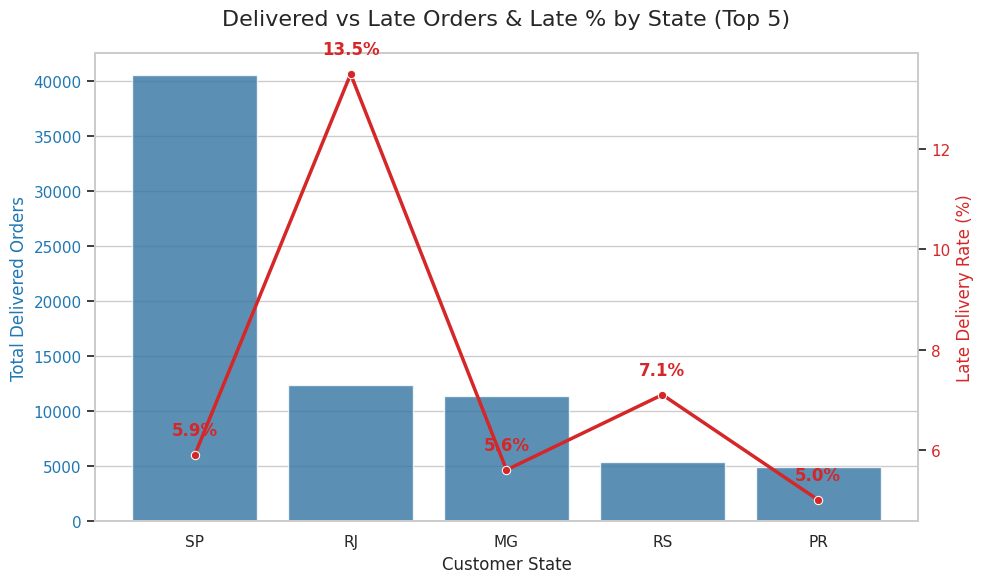

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style and figure size
sns.set_theme(style="whitegrid")
fig, ax1 = plt.subplots(figsize=(10, 6))

# Create a primary bar chart for total delivered orders
color_delivered = '#1f77b4'
sns.barplot(
    x='state',
    y='delivered',
    data=top_5_states,
    color=color_delivered,
    ax=ax1,
    alpha=0.8
)
ax1.set_title('Delivered vs Late Orders & Late % by State (Top 5)', fontsize=16, pad=20)
ax1.set_xlabel('Customer State', fontsize=12)
ax1.set_ylabel('Total Delivered Orders', color=color_delivered, fontsize=12)
ax1.tick_params(axis='y', labelcolor=color_delivered)

# Instantiate a second axes that shares the same x-axis for the Late % line
ax2 = ax1.twinx()
color_pct = '#d62728'
sns.lineplot(
    x='state',
    y='late_pct',
    data=top_5_states,
    color=color_pct,
    marker='o',
    linewidth=2.5,
    ax=ax2
)
ax2.set_ylabel('Late Delivery Rate (%)', color=color_pct, fontsize=12)
ax2.tick_params(axis='y', labelcolor=color_pct)
ax2.grid(False)  # Avoid overlapping grid lines

# Add data labels for the percentages
for x_val, y_val in zip(range(len(top_5_states)), top_5_states['late_pct']):
    ax2.text(x_val, y_val + 0.4, f"{y_val}%", color=color_pct, ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

**Q6. Delivery punctuality vs satisfaction**
Advanced feature · filterable — call with multi_params(...); the table below is the All result.
--- result not verified

In [ ]:
%%sql
SELECT CASE WHEN o.order_delivered_customer_date <= o.order_estimated_delivery_date
            THEN 'On Time' ELSE 'Late' END AS delivery_status,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),3) AS avg_score,
       ROUND(AVG(julianday(o.order_delivered_customer_date)
               - julianday(o.order_purchase_timestamp)),2) AS avg_delivery_days
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status='delivered' AND o.order_delivered_customer_date IS NOT NULL
  AND (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY 1 ORDER BY avg_score DESC

,delivery_status,orders,avg_score,avg_delivery_days
0,On Time,88163,4.294,10.88
1,Late,7661,2.566,31.39


**Q7. Average days late when late**
Diagnostic · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [ ]:
%%sql
SELECT COUNT(*) AS late_orders,
       ROUND(AVG(julianday(order_delivered_customer_date)
               - julianday(order_estimated_delivery_date)),2) AS avg_days_late,
       ROUND(MAX(julianday(order_delivered_customer_date)
               - julianday(order_estimated_delivery_date)),0) AS worst_days_late
FROM orders
WHERE order_status='delivered'
  AND order_delivered_customer_date > order_estimated_delivery_date

,late_orders,avg_days_late,worst_days_late
0,7826,9.55,189.0


**Q8. Review volume by month**
Chart support · filterable — call with year_params(...); the table below is the All result

In [ ]:
%%sql
SELECT strftime('%Y', o.order_purchase_timestamp) AS year,
       COUNT(*) AS reviews
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY year ORDER BY year

,year,reviews
0,2016,326
1,2017,45044
2,2018,53854


**Q9. Satisfaction by delivery-time bucket**:
Analysis · filterable — call with year_params(...); the table below is the All result

In [26]:
%%sql
SELECT CASE
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 5  THEN '0-5 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 10 THEN '6-10 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 20 THEN '11-20 days'
         WHEN julianday(o.order_delivered_customer_date)-julianday(o.order_purchase_timestamp) <= 30 THEN '21-30 days'
         ELSE '30+ days' END AS delivery_bucket,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_status='delivered' AND o.order_delivered_customer_date IS NOT NULL
  AND (:selected_year = 'All' OR strftime('%Y', o.order_purchase_timestamp) = :selected_year)
GROUP BY 1 ORDER BY 1

,delivery_bucket,orders,avg_score
0,0-5 days,13374,4.45
1,11-20 days,35547,4.22
2,21-30 days,9588,3.69
3,30+ days,4430,2.25
4,6-10 days,32885,4.36


**Q10. Reviews fan-out diagnostic**

Data quality · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [28]:
%%sql
SELECT COUNT(*) AS review_rows, COUNT(DISTINCT order_id) AS distinct_orders,
       COUNT(*) - COUNT(DISTINCT order_id) AS duplicate_rows
FROM order_reviews

,review_rows,distinct_orders,duplicate_rows
0,99224,98673,551


**Q11. Distinct customers vs customer rows**

Data quality · not filterable — this is a whole-dataset fact, so it deliberately has no ? guard

In [29]:
%%sql
SELECT (SELECT COUNT(*) FROM customers) AS customer_rows,
       (SELECT COUNT(DISTINCT customer_unique_id) FROM customers) AS unique_customers

,customer_rows,unique_customers
0,99441,96096


**Q12. Lowest-scoring states (min 2,000 orders)**

Insight · filterable — call with multi_params(...); the table below is the All result

In [32]:
%%sql
SELECT c.customer_state AS state,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(AVG(CAST(r.review_score AS REAL)),2) AS avg_score
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
JOIN order_reviews r  ON o.order_id  = r.order_id
WHERE (:state_json = '[]' OR c.customer_state IN (SELECT value FROM json_each(:state_json)))
GROUP BY state HAVING orders >= 2000
ORDER BY avg_score ASC LIMIT 10

,state,orders,avg_score
0,BA,3340,3.86
1,RJ,12687,3.87
2,ES,2006,4.04
3,GO,2007,4.04
4,DF,2128,4.06
5,SC,3609,4.07
6,RS,5443,4.13
7,MG,11554,4.14
8,SP,41472,4.17
9,PR,5019,4.18
